# EV Charging Demand Regression Project

## Project objective
The goal is to predict the charging demand of an EV charging session using regression models.

We give the model information about a charging session, such as:
- charging duration,
- month/day/hour,
- location,
- charger type/company,
- previous usage counts,
and ask the model to estimate the numerical **demand** value.

### Complete workflow
1. Load and prepare the dataset.
2. Remove columns that should not be used for prediction.
3. Check the dataset size, columns, and missing values.
4. Check simple correlations with the target (`demand`).
5. Separate input features (`X`) and target (`y`).
6. Use a chronological 80/20 train-test split.
7. Preprocess numeric and categorical features.
8. Train six regression models.
9. Compare MAE, MSE, RMSE, R², and Train/Test R².
10. Inspect LightGBM feature importance.
11. Study residual graphs to understand model errors.

### Important terms
- **Feature:** an input column used to make a prediction.
- **Target:** the value we want to predict. Here, the target is `demand`.
- **Training data:** data used by the model to learn patterns.
- **Test data:** later unseen data used to check whether the learned pattern generalizes.
- **Regression:** a machine-learning task that predicts a numerical value.

## 1. File backup, loading, chronological sorting, and column removal

Before training a model, we prepare a clean modeling dataset.

### Code explanation
- `import pandas as pd` imports pandas for working with tabular data.
- `pd.read_csv(...)` loads the dataset into the DataFrame `df`.
- `pd.to_datetime(df['start_full'])` converts the starting timestamp into a true datetime value.
- `sort_values("start_full")` arranges records from earliest to latest.
- `reset_index(drop=True)` creates a clean sequential index after sorting.

### Why sorting is important
The **first 80%** of rows for training and the **last 20%** for testing. Therefore, sorting by `start_full` first ensures that training uses older records and testing uses newer records.

### Why columns are removed
The `columns_to_remove` list removes:
- identifier columns such as `userid` and `chargerid`,
- raw date/time columns that are no longer required,
- end-time-related information that may not be available at prediction time,
- intermediate cleaning/check columns,
- duplicate/redundant date-category columns.

`errors='ignore'` means pandas will not stop with an error if one of those columns is already absent.

Finally, the cleaned DataFrame is saved back to `ev_charging_featured_model.csv`.

In [20]:
import pandas as pd

# 1. Load the feature-engineered EV charging dataset
df = pd.read_csv('data/ev_charging_featured.csv')

# 2. Convert the starting timestamp to datetime and sort records from oldest to newest
# This order is required for the chronological train-test split used later.
df['start_full'] = pd.to_datetime(df['start_full'])
df = df.sort_values("start_full").reset_index(drop=True)

# 3. List columns that should not be used in the regression models
columns_to_remove = [
    'userid', 'chargerid', 'startday', 'starttime', 'endday', 'endtime',
    'startdatetime', 'enddatetime', 'end_full',
    'duration_original', 'duration_calculated', 'duration_mismatch',
    'duration_outlier', 'demand_outlier', 'day_name', 'month_name',
    'is_weekday', 'day_type','start_date','chargercompany_label', 'chargertype_label', 'log_demand'
]

# 4. Drop the listed columns safely
df = df.drop(columns=columns_to_remove, errors='ignore')

# 5. Save the cleaned modeling dataset back to the working CSV
df.to_csv('data/ev_charging_featured_model.csv', index=False)
print("Columns removed successfully! Updated file saved to ev_charging_featured_model.csv")

Columns removed successfully! Updated file saved to ev_charging_featured_model.csv


## 2. Dataset size

`df.shape` returns: (rows and column records)

The output is **(72,241, 18)**, which means:
- **72,241 charging-session records**
- **18 remaining columns**

This check confirms the amount of data available after column removal.

In [21]:
df.shape

(72241, 19)

## 3. Remaining columns

`df.columns` displays every column that remains after preprocessing.

### How to read these columns
- **Target:** `demand`
- **Main numerical/session feature:** `duration`
- **Calendar/time features:** `start_year`, `start_month`, `start_day`, `start_hour`, `start_minute`, `day_of_week_number`, `week_of_year`, `is_weekend`
- **Categorical/context features:** `chargercompany`, `location`, `chargertype`, `time_of_day`
- **Historical usage features:** `user_previous_sessions`, `charger_previous_sessions`, `location_previous_sessions`
- **Additional transformed feature:** `log_duration`

In [22]:
df.columns

Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'day_of_week_number', 'log_duration',
       'start_year', 'start_month', 'start_day', 'start_minute',
       'week_of_year', 'is_weekend', 'time_of_day', 'user_previous_sessions',
       'charger_previous_sessions', 'location_previous_sessions'],
      dtype='object')

## 4. Missing-value check

Check missing values column by column and all selected columns. `df.isnull().sum()` counts missing values in every column.

### Output
Every column shows **0**, so there are no missing values in the current modeling dataset.

In [23]:
df.isnull().sum()

chargercompany                0
location                      0
chargertype                   0
duration                      0
demand                        0
start_full                    0
start_hour                    0
day_of_week_number            0
log_duration                  0
start_year                    0
start_month                   0
start_day                     0
start_minute                  0
week_of_year                  0
is_weekend                    0
time_of_day                   0
user_previous_sessions        0
charger_previous_sessions     0
location_previous_sessions    0
dtype: int64

## 5. Feature availability validation

Check required `features` are available in dataframe.

- The list stores the feature names that should exist.
- The list comprehension checks each expected feature against `df.columns`.
- Any absent feature is stored in `missing_cols`.
- If the list is empty, the code prints that all features are present.

The output confirms that **all required features are available**.

In [24]:
features = [
    'chargercompany',
    'location',
    'chargertype',
    'duration',
    'start_month',
    'start_day',
    'start_hour',
    'start_minute',
    'day_of_week_number',
    'week_of_year',
    'is_weekend',
    'time_of_day'
    #'user_previous_sessions',
    #'charger_previous_sessions',
    #'location_previous_sessions'
]

# Check whether every required modeling feature exists in the DataFrame
missing_cols = [col for col in features if col not in df.columns]

# Report the result clearly
if not missing_cols:
    print("All features are present in the DataFrame!")
else:
    print(f"Missing columns ({len(missing_cols)}):", missing_cols)


All features are present in the DataFrame!


## 6. Correlation with demand

### correlation means
Correlation measures the **linear relationship** between two numerical variables.

- Close to **+1** → strong positive linear relationship.
- Close to **0** → weak/no linear relationship.
- Close to **-1** → strong negative linear relationship.

The code first keeps numerical columns, calculates the correlation matrix, selects only correlations with `demand`, and sorts them from highest to lowest.

### Interpretation
- `demand = 1.0000` appears because a variable is perfectly correlated with itself.
- `duration = 0.6009` has the strongest positive linear relationship with demand.
- `log_duration = 0.5857` is also moderately positively related to demand.
- `start_hour = 0.1283` has only a weak positive linear relationship.
- Most other features have weak individual linear relationships with demand. However, tree-based models can still use them effectively through nonlinear patterns and feature interactions.

Also, `chargercompany` and `chargertype` appear in this numeric correlation because they are numerically stored in the DataFrame, but later the notebook deliberately treats them as **categorical features**.

In [25]:
# Select only columns currently stored as numeric and calculate pairwise correlations
corr = df.select_dtypes(include='number').corr()

# Show each numeric column's correlation with the target and sort from highest to lowest
corr['demand'].sort_values(
    ascending=False
)

demand                        1.000000
duration                      0.600884
log_duration                  0.585666
start_hour                    0.128282
chargertype                   0.062465
chargercompany                0.041412
start_year                    0.016143
location_previous_sessions    0.015141
charger_previous_sessions     0.012825
day_of_week_number            0.009823
is_weekend                    0.007499
start_month                  -0.006080
start_day                    -0.006460
week_of_year                 -0.006950
start_minute                 -0.007296
user_previous_sessions       -0.036799
Name: demand, dtype: float64

## 7. Imports, feature groups, target, chronological split, and preprocessing

### A. Imported tools
- `numpy` is used for numerical calculations such as square root.
- `Pipeline` joins preprocessing and a model into one safe workflow.
- `ColumnTransformer` applies different preprocessing to numeric and categorical columns.
- `StandardScaler` scales numerical columns.
- `OneHotEncoder` converts categorical values into machine-readable dummy columns.
- `mean_absolute_error`, `mean_squared_error`, and `r2_score` evaluate regression predictions.
- `LinearRegression` is the first regression model used later.

### B. Numeric features
The numerical model inputs are:
- charging duration,
- calendar/time values,
- weekend indicator,
- previous-session counts.

### C. Categorical features
The categorical model inputs are:
- location,
- time of day,
- charger type,
- charger company.

### D. Features (`X`) and target (`y`)
- `x` = columns given to the model as inputs.
- `y` = `demand`, the numerical value the model must predict.

### E. Chronological 80/20 split
`split_idx = int(len(df) * 0.80)` finds the row that separates the first 80% from the last 20%.

Because the DataFrame was already sorted by `start_full`:
- earliest 80% → training data,
- latest 20% → test data.

No random shuffle is used.

### Why chronological splitting is appropriate here
For time-related data, we want to imitate the real situation: **learn from the past and predict newer records**. Randomly mixing future rows into training could give an unrealistically easy test.

### F. Preprocessing
For numerical features:
- `StandardScaler()` transforms values to a common scale, roughly centered around mean 0 with standard deviation 1.

For categorical features:
- `OneHotEncoder(...)` creates binary dummy columns.
- `drop='first'` removes one dummy level from each category group.
- `handle_unknown='ignore'` prevents an error if a category appears in test data that was not seen during training.

`ColumnTransformer` keeps these two preprocessing processes separate and applies each to the correct columns.

log_duration was not used in the final models because duration already captured similar information and was easier to explain.

Although start_year remained in the dataframe, it was excluded from modeling because it showed very weak correlation with demand and did not provide meaningful predictive value.

### Leakage protection
Because preprocessing is placed inside a `Pipeline`, scaling and encoding are **fit on the training data** when the pipeline is trained, then applied to the test data. This avoids learning preprocessing information from the test set.

### Note about tree models
Decision Tree, Random Forest, LightGBM, Gradient Boosting, and XGBoost generally do not require numerical scaling. However, using the same preprocessing pipeline gives a consistent input workflow across all models.

In [26]:
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression


# 1. Define numerical input features
numeric_features = [
    'duration',
    'start_month',
    'start_day',
    'start_hour',
    'start_minute',
    'day_of_week_number',
    'week_of_year',
    'is_weekend'
    #'user_previous_sessions',
    #'charger_previous_sessions',
    #'location_previous_sessions'
]

# 2. Define categorical input features
categorical_features = [
    'location',
    'time_of_day',
    'chargertype',
    'chargercompany',
]

# 3. Separate model inputs (x) and regression target (y)
x = df[numeric_features + categorical_features]
y = df['demand']

# 4. Create an 80/20 chronological split.
# The DataFrame was sorted by start time earlier, so no shuffling is used.
split_idx = int(len(df) * 0.80)

x_train = x.iloc[:split_idx]
x_test = x.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# 5. Build preprocessing:
#    - scale numerical features
#    - one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)


# 8. Model 1 — Linear Regression

## What is Linear Regression?
Linear Regression tries to predict the target using a **straight-line/linear relationship** between the input features and demand.

In simple form:

**Predicted demand = intercept + contributions from the input features**

Each feature receives a coefficient. The model combines those coefficients to make a numerical prediction.

### usage
- Simple and easy to explain.
- Fast to train.
- Good baseline model.
- Helps us see whether the problem can be represented reasonably well by a linear relationship.

### Limitation
If the true relationship between features and demand is nonlinear or contains complex interactions, Linear Regression may miss those patterns.

In [27]:
# 1. Build a pipeline: preprocessing first, then Linear Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# 2. Train the model using the older 80% of records
lr_pipeline.fit(x_train, y_train)

# 3. Predict demand for the newer 20% test records
y_pred_lr = lr_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

# 5. Print test metrics and compare training R² with test R²
print("=== Linear Regression Results (Standard Features Only) ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {lr_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== Linear Regression Results (Standard Features Only) ===
MAE  (Mean Absolute Error) : 7.0668
MSE  (Mean Squared Error)  : 112.2825
RMSE (Root Mean Sq Error)  : 10.5963
R² Score                   : 0.4176
Train R² : 0.5085
Test  R² : 0.4176


### Linear Regression results

**Observed test results**
- MAE = **7.0809**
- MSE = **112.3343**
- RMSE = **10.5988**
- Test R² = **0.4173**
- Train R² = **0.5089**

#### Interpreation
MAE says the predictions differ from the actual demand by about **7.08 units on average**.

RMSE is higher at **10.60**, which tells us that some larger errors are present because RMSE penalizes large errors more strongly.

Test R² = **0.4173** means the model captures about **41.7% of the variation in unseen test demand**.

Train R² and Test R² are not extremely far apart. Therefore, the biggest issue is not severe overfitting; the more important issue is that a linear model is too simple for the full relationship.

**Conclusion:** Linear Regression provides a useful baseline model. However, its relatively low Test R² suggests that charging demand depends on nonlinear relationships that cannot be fully captured by a simple linear model.

# 9. Model 2 — Decision Tree Regressor

## What is a Decision Tree Regressor?
A Decision Tree predicts a numerical value by repeatedly splitting the data into smaller groups using questions such as:

- Is duration below a particular value?
- Is the start hour above a particular value?
- Is the location one category or another?

After several splits, a final leaf gives the predicted demand.

### usage
- Can learn **nonlinear** relationships.
- Can capture feature interactions.
- Does not require a straight-line relationship.

### Why `max_depth=10`?
`max_depth` limits how many levels the tree can grow. A very deep tree can memorize training data, so limiting depth is one way to reduce overfitting.

In [28]:
from sklearn.tree import DecisionTreeRegressor

# 1. Build a Decision Tree pipeline.
# max_depth=10 limits tree growth to reduce excessive memorization.
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(max_depth=10, random_state=42))
])

# 2. Train the model
dt_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_dt = dt_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)

# 5. Print test metrics and compare training R² with test R²
print("=== Decision Tree Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {dt_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== Decision Tree Regressor Results ===
MAE  (Mean Absolute Error) : 4.5417
MSE  (Mean Squared Error)  : 71.7114
RMSE (Root Mean Sq Error)  : 8.4683
R² Score                   : 0.6280
Train R² : 0.8247
Test  R² : 0.6280


### Decision Tree results

**Observed test results**
- MAE = **4.8980**
- MSE = **84.4981**
- RMSE = **9.1923**
- Test R² = **0.5617**
- Train R² = **0.8410**

### interpretation

The Decision Tree improves all test metrics compared with Linear Regression. This means nonlinear splitting captures more useful structure.

However, Train R² is **0.8410** while Test R² is only **0.5617**. The gap is about **0.2793**, which is large.

**Conclusion:** better predictive power than Linear Regression, but noticeable overfitting.

# 10. Model 3 — LightGBM Regressor

## What is LightGBM?
LightGBM is a **gradient-boosting tree model**.

Instead of building one tree only, it builds many small trees. Each new tree tries to improve the errors made by the previous trees. Their combined prediction is usually much stronger than a single tree.

### Main parameters used here
- `n_estimators=100`: build 100 boosting trees.
- `learning_rate=0.1`: controls how strongly each new tree changes the overall prediction.
- `random_state=42`: makes the experiment more reproducible.
- `verbose=-1`: suppresses training messages.

### usage
LightGBM is good at:
- nonlinear patterns,
- feature interactions,
- larger tabular datasets,
- complex relationships that Linear Regression may miss.

In [29]:
import lightgbm as lgb

# 1. Build the LightGBM pipeline
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', lgb.LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbose=-1
    ))
])

# 2. Train the boosting model
lgb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_lgb = lgb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lgb)
mse = mean_squared_error(y_test, y_pred_lgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lgb)

# 5. Print test metrics and compare training R² with test R²
print("=== LightGBM Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {lgb_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== LightGBM Regressor Results ===
MAE  (Mean Absolute Error) : 4.2884
MSE  (Mean Squared Error)  : 57.4821
RMSE (Root Mean Sq Error)  : 7.5817
R² Score                   : 0.7018
Train R² : 0.8335
Test  R² : 0.7018


### LightGBM results

**Observed test results**
- MAE = **4.1483**
- MSE = **54.1649**
- RMSE = **7.3597**
- Test R² = **0.7190**
- Train R² = **0.8535**

### interpretation
This is the strongest result in the notebook:
- the average absolute error is the lowest,
- large-error-sensitive RMSE is also the lowest,
- Test R² is the highest.

A Test R² of **0.7190** means the model captures about **71.9% of the variation in the test demand values**.

Train R² is higher than Test R², so there is still some generalization gap, but the test performance remains the best among the compared models.

**Conclusion:** LightGBM was selected as the final regression model because it achieved the lowest prediction errors (MAE, MSE, RMSE) and the highest Test R² score among all evaluated models.

# 11. Model 4 — Gradient Boosting Regressor

## What is Gradient Boosting?
Gradient Boosting also builds trees **sequentially**.

The first tree makes an initial prediction. The next tree focuses on correcting remaining errors. This process repeats, and all trees work together to produce the final prediction.

### Main parameters used here
- `n_estimators=100`: number of boosting stages.
- `learning_rate=0.1`: contribution of each new stage.
- `max_depth=5`: limits the depth of each individual tree.
- `random_state=42`: reproducibility.

### usage
It can model nonlinear relationships and usually performs much better than a single Decision Tree when the parameters are suitable.

In [30]:
from sklearn.ensemble import GradientBoostingRegressor

# 1. Build the Gradient Boosting pipeline
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])

# 2. Train the model
gb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_gb = gb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_gb)

# 5. Print test metrics and compare training R² with test R²
print("=== Gradient Boosting Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {gb_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== Gradient Boosting Regressor Results ===
MAE  (Mean Absolute Error) : 4.3326
MSE  (Mean Squared Error)  : 58.8461
RMSE (Root Mean Sq Error)  : 7.6711
R² Score                   : 0.6947
Train R² : 0.8233
Test  R² : 0.6947


### Gradient Boosting results

**Observed test results**
- MAE = **4.3462**
- MSE = **57.3026**
- RMSE = **7.5698**
- Test R² = **0.7028**
- Train R² = **0.8382**

### Interpretation

The model captures about **70.3% of test-set variation** and has much lower error than Linear Regression or the single Decision Tree.

It is a strong model, but LightGBM has slightly lower error and slightly higher Test R².

**Conclusion:** strong model, slightly behind LightGBM and XGBoost models.

# 12. Model 5 — XGBoost Regressor

## What is XGBoost?
XGBoost is another powerful gradient-boosting tree algorithm.

Like other boosting methods, it adds trees step by step so later trees correct earlier errors. XGBoost also includes optimization and regularization techniques designed to make boosting efficient and control overfitting.

### Main parameters used here
- `n_estimators=100`: number of trees.
- `learning_rate=0.1`: size of each boosting update.
- `max_depth=5`: maximum depth of individual trees.
- `random_state=42`: reproducibility.

### Why compare it with LightGBM?
Both are strong boosting algorithms, but their tree-building methods and implementations differ. The best one depends on the dataset, so comparing their test metrics is better than assuming one will always win.

In [31]:
import xgboost as xgb

# 1. Build the XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])

# 2. Train the model
xgb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_xgb = xgb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)

# 5. Print test metrics and compare training R² with test R²
print("=== XGBoost Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {xgb_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== XGBoost Regressor Results ===
MAE  (Mean Absolute Error) : 4.3175
MSE  (Mean Squared Error)  : 58.4350
RMSE (Root Mean Sq Error)  : 7.6443
R² Score                   : 0.6969
Train R² : 0.8185
Test  R² : 0.6969


### XGBoost results

**Observed test results**
- MAE = **4.2197**
- MSE = **55.4963**
- RMSE = **7.4496**
- Test R² = **0.7121**
- Train R² = **0.8361**

### Interpretation
XGBoost captures about **71.2% of the variation in unseen test demand**.

Its result is very close to LightGBM:
- LightGBM Test R² = 0.7190
- XGBoost Test R² = 0.7121

LightGBM still has slightly lower MAE/RMSE and slightly higher Test R².

**Conclusion:** Second best model, very close to LightGBM.

# 13. Model 6 — Random Forest Regressor

## What is Random Forest?
Random Forest builds **many Decision Trees independently** using random samples and random subsets of features. The final regression prediction is the average of the trees' predictions.

### Why is it different from boosting?
- **Random Forest:** many trees are built more independently and then averaged.
- **Boosting:** trees are built sequentially, where each new tree tries to correct previous errors.

### Main parameters used here
- `n_estimators=100`: build 100 trees.
- `max_depth=12`: limits the depth of each tree.
- `random_state=42`: reproducibility.
- `n_jobs=-1`: use all available CPU cores for training.

### usage
Averaging many trees usually makes Random Forest more stable than a single Decision Tree and reduces variance.

In [32]:
from sklearn.ensemble import RandomForestRegressor

# 1. Build a Random Forest pipeline.
# n_jobs=-1 uses all available CPU cores for faster training.
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train the model
rf_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_rf = rf_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

# 5. Print test metrics and compare training R² with test R²
print("=== Random Forest Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")
print(f"Train R² : {rf_pipeline.score(x_train, y_train):.4f}")
print(f"Test  R² : {r2:.4f}")


=== Random Forest Regressor Results ===
MAE  (Mean Absolute Error) : 4.3341
MSE  (Mean Squared Error)  : 60.8289
RMSE (Root Mean Sq Error)  : 7.7993
R² Score                   : 0.6845
Train R² : 0.8783
Test  R² : 0.6845


### Random Forest results

**Observed test results**
- MAE = **4.5933**
- MSE = **59.7860**
- RMSE = **7.7321**
- Test R² = **0.6899**
- Train R² = **0.8957**

### interpretation

Random Forest captures about **69.0% of the test variation**, so it performs much better than Linear Regression and the single Decision Tree.

However, the Train R² is **0.8957**, much higher than Test R² **0.6899**. The gap of about **0.2058** indicates more overfitting than the boosting models.

**Conclusion:** strong model, but boosting models generalize better in this experiment.

# 14. LightGBM feature importance

Since LightGBM gives the best test metrics among the six models ,this section examines which features it used most often.

### What feature importance means here
`model.feature_importances_` returns LightGBM's default **split importance**: how many times a feature was used to split the training data across the trees.

Therefore:
- higher importance means the feature contributed more frequently to decision-making splits across the LightGBM trees.
- it does **not** mean the feature increases demand,
- it does **not** mean an importance value of 825 equals 825 units of demand.

### How the code works
1. Get the trained LightGBM model from the pipeline.
2. Reconstruct all final feature names:
   - numeric feature names remain the same,
   - categorical values have been one-hot encoded into new dummy columns.
3. Pair each feature name with its importance score.
4. Sort from highest importance to lowest.
5. Display the top 20.

### Output
The strongest features are:
1. `duration` — 825
2. `user_previous_sessions` — 400
3. `location_previous_sessions` — 298
4. `charger_previous_sessions` — 250
5. `start_hour` — 208

This tells us that **charging duration and historical charging behavior are very influential for this LightGBM model**, while time and location/charger context also contribute.

In [33]:
# Extract the trained LightGBM estimator from the pipeline
model = lgb_pipeline.named_steps['model']

# Reconstruct feature names after preprocessing.
# Numerical names stay unchanged, while categorical columns become one-hot encoded names.
feature_names = (
    numeric_features +
    list(
        lgb_pipeline.named_steps['preprocessor']
        .named_transformers_['cat']
        .get_feature_names_out(categorical_features)
    )
)

# Pair each transformed feature with its LightGBM importance score
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': model.feature_importances_
})

# Sort from most-used feature to least-used feature
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display the 20 most important features
print(importance_df.head(20))


                        Feature  Importance
0                      duration        1011
3                    start_hour         328
6                  week_of_year         303
4                  start_minute         225
25             chargercompany_1         146
2                     start_day         129
24                chargertype_1         109
1                   start_month         103
5            day_of_week_number          96
8            location_apartment          77
14              location_market          57
13               location_hotel          52
18              location_resort          50
15         location_public area          47
11             location_company          47
16  location_public institution          45
17  location_public parking lot          37
19          location_restaurant          25
23            time_of_day_Night          20
21          time_of_day_Evening          19


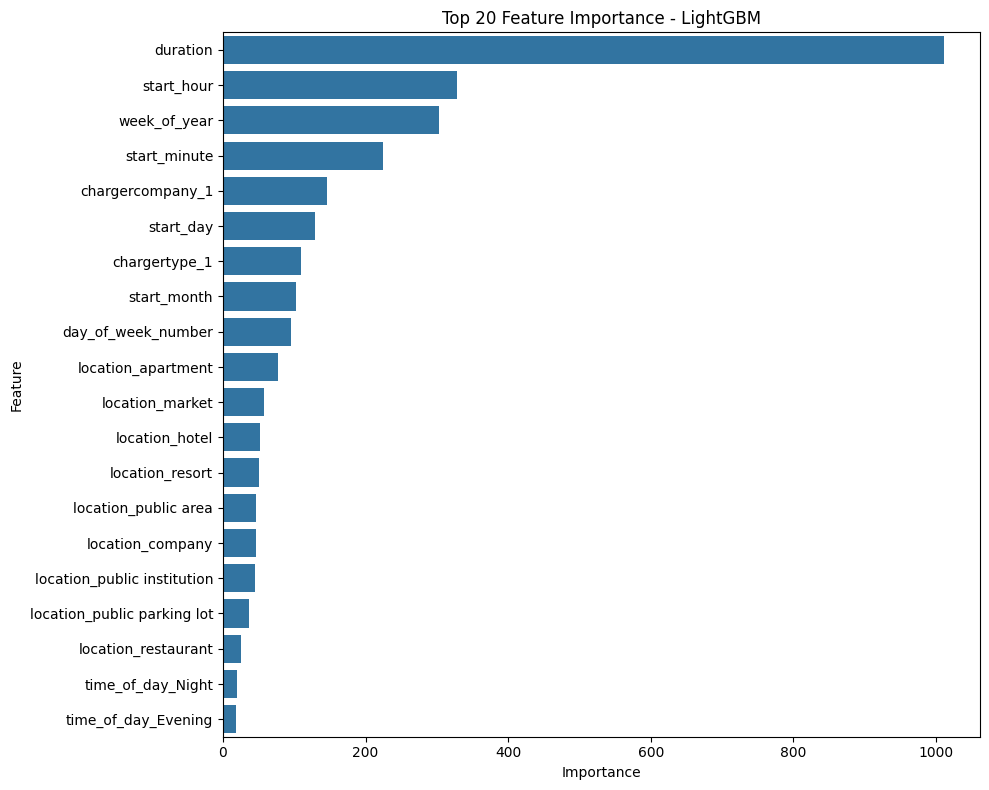

In [34]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("images", exist_ok=True)


# Take top 20 important features
top_features = importance_df.head(20)


plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Feature Importance - LightGBM"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()


# Save image
plt.savefig(
    "images/lightgbm_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 15. Final model comparison and project interpretation


## How to understand the evaluation metrics

All six models are evaluated on the **same chronological test set**, so their metrics are directly comparable.

### Train R² vs Test R²
- **Train R²** tells how well the model fits records it learned from.
- **Test R²** tells how well it performs on later unseen records.

A very high Train R² but much lower Test R² is a warning sign for **overfitting**.

## Results from this notebook

| Model | MAE ↓ | MSE ↓ | RMSE ↓ | Train R² | Test R² ↑ | Train-Test R² gap |
|---|---:|---:|---:|---:|---:|---:|
| Linear Regression | 7.0809 | 112.3343 | 10.5988 | 0.5089 | 0.4173 | 0.0916 |
| Decision Tree | 4.8980 | 84.4981 | 9.1923 | 0.8410 | 0.5617 | 0.2793 |
| LightGBM | **4.1483** | **54.1649** | **7.3597** | 0.8535 | **0.7190** | 0.1345 |
| Gradient Boosting | 4.3462 | 57.3026 | 7.5698 | 0.8382 | 0.7028 | 0.1354 |
| XGBoost | 4.2197 | 55.4963 | 7.4496 | 0.8361 | 0.7121 | **0.1240** |
| Random Forest | 4.5933 | 59.7860 | 7.7321 | 0.8957 | 0.6899 | 0.2058 |

## Model-by-model interpretation

### 1. Linear Regression
- MAE = **7.0809**
- RMSE = **10.5988**
- Test R² = **0.4173**
- Train R² = **0.5089**

This is the weakest model in the comparison. It captures about **41.7% of the test-set variation**. The relatively small train-test gap shows that extreme overfitting is not the main problem; instead, a simple linear relationship is not flexible enough for the data.


### 2. Decision Tree
- MAE = **4.8980**
- RMSE = **9.1923**
- Test R² = **0.5617**
- Train R² = **0.8410**

It improves strongly over Linear Regression, showing that nonlinear splits are useful. However, the R² falls from **0.8410 on training data to 0.5617 on test data**, a gap of about **0.2793**. This is a clear sign of noticeable overfitting.

> “The Decision Tree learns nonlinear patterns, but the large train-test R² gap shows that it fits training data much better than unseen data.”

### 3. LightGBM
- MAE = **4.1483**
- RMSE = **7.3597**
- Test R² = **0.7190**
- Train R² = **0.8535**

LightGBM gives the **lowest MAE, lowest MSE, lowest RMSE, and highest Test R²** in this notebook. It therefore provides the strongest overall predictive performance among the tested models.

There is still a noticeable gap between the Train R² and Test R², which indicates some overfitting. However, LightGBM still shows the best performance on unseen data compared with the other models tested.


### 4. Gradient Boosting
- MAE = **4.3462**
- RMSE = **7.5698**
- Test R² = **0.7028**
- Train R² = **0.8382**

This is also a strong model. It captures about **70.3% of test variation**, but its errors are slightly larger than LightGBM and XGBoost.


### 5. XGBoost
- MAE = **4.2197**
- RMSE = **7.4496**
- Test R² = **0.7121**
- Train R² = **0.8361**

XGBoost is the **second-best model by Test R²** and is very close to LightGBM. It also has the smallest train-test R² gap among the three boosting models shown here.


### 6. Random Forest
- MAE = **4.5933**
- RMSE = **7.7321**
- Test R² = **0.6899**
- Train R² = **0.8957**

Random Forest performs well on test data, but its training score is much higher than its test score. The gap of about **0.2058** indicates more overfitting than the boosting models.


## Final model choice
Based on the interpretation, **LightGBM is the best model among the six tested regression models** because it has:
- the lowest MAE,
- the lowest MSE,
- the lowest RMSE,
- the highest Test R².

# 16. Residual analysis

## What is a residual?
A residual is the prediction error for one record.

**Residual = Actual demand - Predicted demand**

Therefore:
- residual = **0** → perfect prediction,
- residual **> 0** → actual demand was higher than predicted → model **underpredicted**,
- residual **< 0** → predicted demand was higher than actual → model **overpredicted**.

## usage
Evaluation metrics give one summary number, but residual plots show **where and how the model makes mistakes**.

Each model produces two graphs:

### Left graph — Residual Distribution
This histogram shows how residual errors are distributed.

A good sign:
- a tall concentration close to 0,
- fewer very large positive or negative errors.

Long tails mean some records have large prediction errors.

### Right graph — Residual vs Predicted Demand
- X-axis = predicted demand.
- Y-axis = residual.
- Red dashed line = residual 0, meaning perfect prediction.

An ideal residual plot looks like a random cloud around the red zero line with a fairly similar vertical spread across prediction values.

Patterns such as a triangle, funnel, curve, or bands tell us the errors are systematic rather than completely random.

### concept
Because residual is calculated as `actual - predicted`:
- dots **above** the red line = underprediction,
- dots **below** the red line = overprediction.

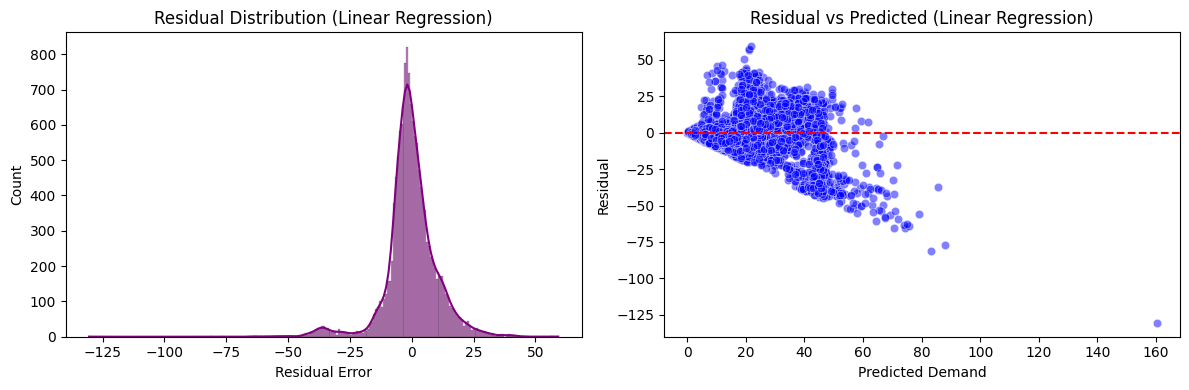

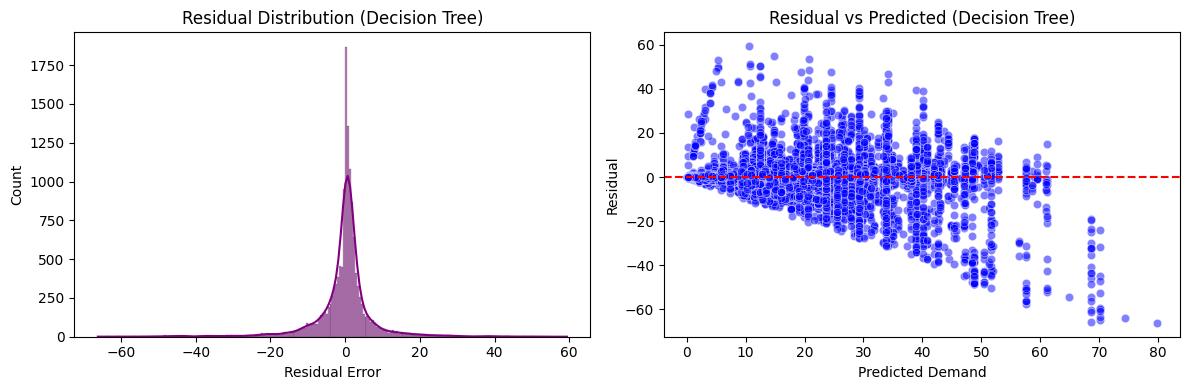

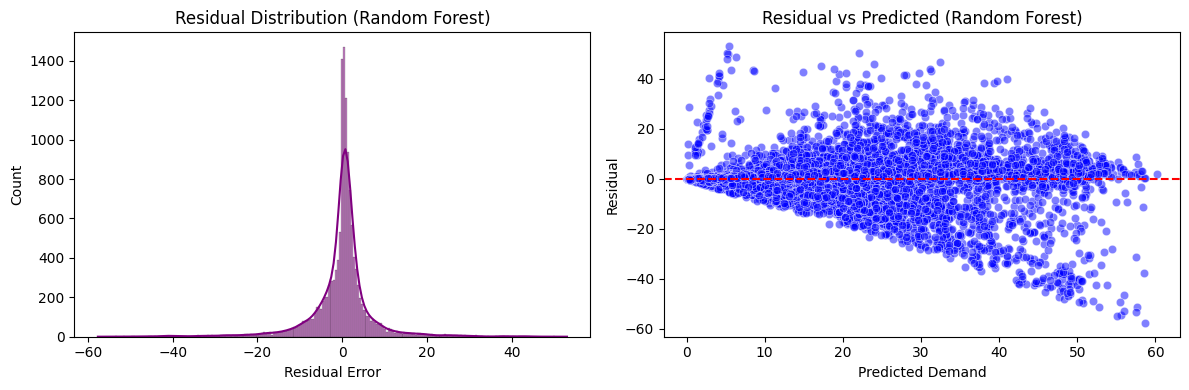

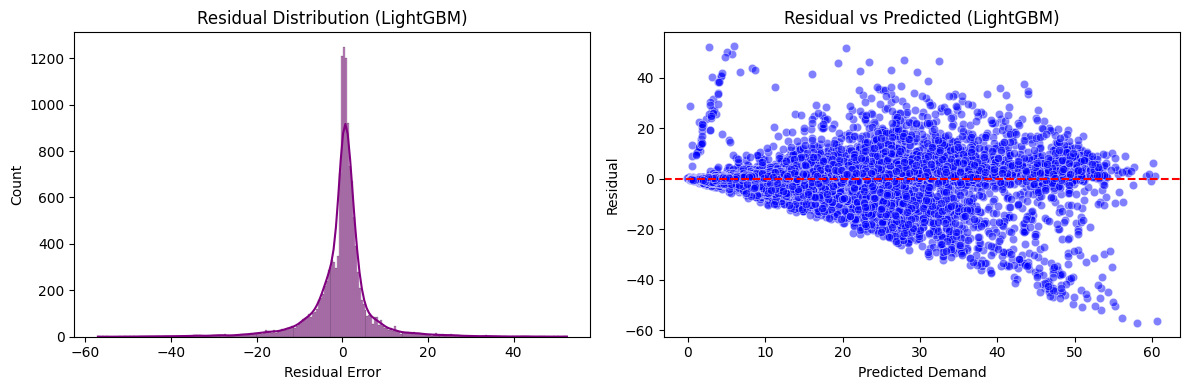

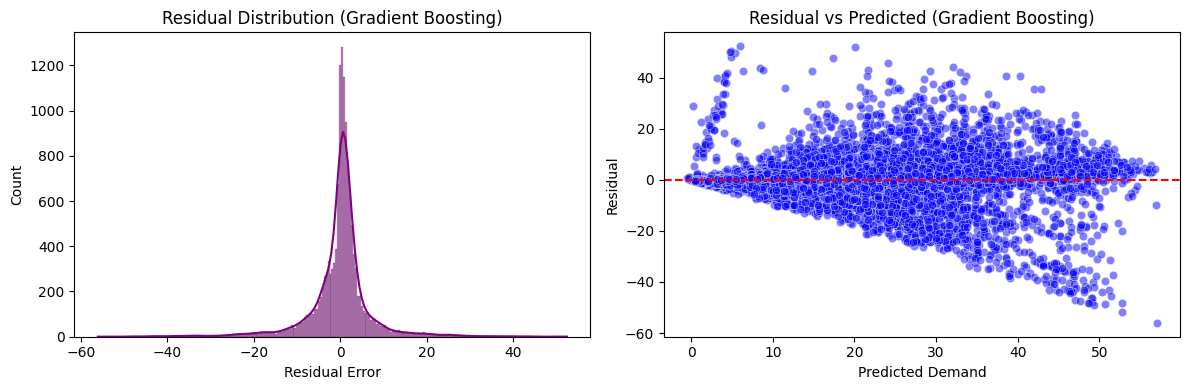

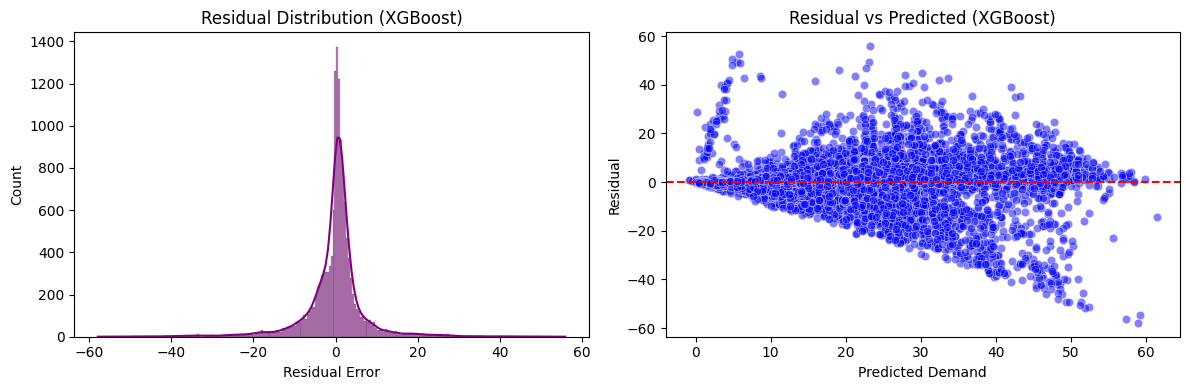

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create a folder to store dashboard images
os.makedirs("images", exist_ok=True)

def analyze_residuals(y_test, y_pred, model_name):
    # Residual = actual demand - predicted demand
    residuals = y_test - y_pred

    # Create one figure containing two residual-analysis plots
    plt.figure(figsize=(12, 4))

    # Left plot: distribution of residual errors
    plt.subplot(1, 2, 1)
    sns.histplot(residuals, kde=True, color='purple')
    plt.title(f"Residual Distribution ({model_name})")
    plt.xlabel("Residual Error")

    # Right plot: residual error against predicted demand
    plt.subplot(1, 2, 2)
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, color='blue')
    plt.axhline(0, color='red', linestyle="--")
    plt.title(f"Residual vs Predicted ({model_name})")
    plt.xlabel("Predicted Demand")
    plt.ylabel("Residual")

    # Prevent plot labels from overlapping
    plt.tight_layout()

    file_name = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"images/residual_{file_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.show()


# Generate residual plots for all six regression models
analyze_residuals(y_test, y_pred_lr, "Linear Regression")
analyze_residuals(y_test, y_pred_dt, "Decision Tree")
analyze_residuals(y_test, y_pred_rf, "Random Forest")
analyze_residuals(y_test, y_pred_lgb, "LightGBM")
analyze_residuals(y_test, y_pred_gb, "Gradient Boosting")
analyze_residuals(y_test, y_pred_xgb, "XGBoost")


## Residual graph interpretation for each model

### 1. Linear Regression
**Residual distribution graph:** Most errors are near zero, but the distribution has long tails, including a very large negative error.

**Residual vs predicted graph:** The points form a strong triangular/downward pattern instead of a random cloud. As predicted demand becomes larger, many residuals move far below zero.

Because negative residual means overprediction, this shows that the model often predicts **too high** for many larger predicted-demand cases. Some positive residuals also show underprediction.

**Meaning:** the linear model is missing important nonlinear structure. This supports its relatively low Test R² of 0.4173.

### 2. Decision Tree
**Residual distribution graph:** Residuals are more tightly centered around zero than Linear Regression.

**Residual vs predicted graph:** There are visible vertical bands and a widening/structured spread rather than a random cloud. Many higher predictions have strongly negative residuals.

**Meaning:** the tree captures more structure than Linear Regression, but error patterns remain and Train R² 0.8410 versus Test R² 0.5617 confirms overfitting.

### 3. Random Forest
**Residual distribution graph:** The residual distribution is narrower and strongly concentrated around zero.

**Residual vs predicted graph:** The cloud is more centered around zero, but a triangular/funnel shape is still visible. The spread becomes large in some middle-to-high prediction ranges, including many negative residuals.

**Meaning:** averaging many trees improves stability compared with a single Decision Tree, but the model still has systematic errors and some overfitting.

### 4. LightGBM
**Residual distribution graph:** Residuals are sharply concentrated around zero, with fewer large errors than the weaker models.

**Residual vs predicted graph:** The cloud is relatively balanced near zero for many cases, although a funnel/triangular pattern remains as predicted demand increases. Some high-prediction cases still fall far below zero.

**Meaning:** LightGBM has the strongest overall metrics and a tight residual distribution. Error size still changes across the prediction range, which means the prediction error is not completely consistent for all predicted values.


### 5. Gradient Boosting
**Residual distribution graph:** Most residuals are near zero, with tails on both sides.

**Residual vs predicted graph:** The pattern is similar to LightGBM, but the spread is somewhat broader in parts of the middle/high prediction range.

**Meaning:** it is a strong model, but its slightly larger MAE/RMSE matches the somewhat broader residual spread.

### 6. XGBoost
**Residual distribution graph:** The distribution is tightly centered around zero.

**Residual vs predicted graph:** Many residuals remain close to the zero line, but a funnel shape and some large negative residuals are still visible at higher predictions.

**Meaning:** the graph agrees with the strong Test R² of 0.7121 and RMSE of 7.4496. It is close to LightGBM but still has systematic high-range errors.

## Overall project takeaway
> “The model comparison shows that EV charging demand is not explained well by a simple linear relationship. Nonlinear ensemble models perform much better. LightGBM gives the best test metrics, while residual analysis shows that all models still have larger errors in some demand ranges.”


## 17. Save the final regression model to a .pkl file

In [36]:
import pickle

with open("models/lightgbm_regression.pkl", "wb") as file:
    pickle.dump(lgb_pipeline, file)

In [37]:
with open("models/lightgbm_regression.pkl", "rb") as file:
    regression_model = pickle.load(file)